# Lab 09 - Notebook 02: SMS Spam Classification with Naive Bayes

**Guided student activity**

In this exercise you will build a spam classifier using the **UCI SMS Spam Collection** dataset. The dataset contains SMS messages labelled as **ham** (legitimate) or **spam**.

Complete the notebook **cell by cell**. Replace each `TODO` with the required code.

### Workflow

**load data -> inspect text -> tokenize -> split -> CountVectorizer -> MultinomialNB -> evaluate -> TF-IDF -> compare**

## Cell 1 - Import the required libraries

Run this cell first. All libraries used in the activity are standard packages commonly available in Python machine-learning environments.

In [19]:
from pathlib import Path
import urllib.request
import zipfile

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

## Cell 2 - Load the SMS Spam Collection dataset

The notebook first looks for a local file called **`SMSSpamCollection`**. If it is not available, it attempts to download the ZIP file from the UCI repository and extract it.

The file has two columns:

- `label`: `ham` or `spam`
- `message`: the SMS text

If your lab environment blocks internet downloads, place the `SMSSpamCollection` file in the same folder as this notebook and run the cell again.

In [20]:
DATA_FILE = Path('SMSSpamCollection')
ZIP_FILE = Path('smsspamcollection.zip')
UCI_URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'

if not DATA_FILE.exists():
    print('Dataset not found locally. Attempting to download it from UCI...')
    try:
        urllib.request.urlretrieve(UCI_URL, ZIP_FILE)
        with zipfile.ZipFile(ZIP_FILE, 'r') as zf:
            zf.extract('SMSSpamCollection', path='.')
        print('Download complete.')
    except Exception as exc:
        raise FileNotFoundError(
            'Could not download the dataset. Download the UCI SMS Spam Collection '
            'manually and place the file named SMSSpamCollection beside this notebook.'
        ) from exc

df = pd.read_csv(DATA_FILE, sep='\t', names=['label', 'message'])
print('Dataset shape:', df.shape)
df.head()

Dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## Cell 3 - Inspect the dataset

Check the class distribution and whether any values are missing.

**Complete the two TODO lines.**

In [21]:
print('Class distribution:')
print(df['label'].value_counts())

# TODO 1: display missing-value counts for each column
print(df.isnull().sum())

# TODO 2: display one spam message and one ham message
display(df[df['label'] == 'spam'].iloc[0]['message'])
display(df[df['label'] == 'ham'].iloc[0]['message'])

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64
label      0
message    0
dtype: int64


"Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's"

'Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...'

## Cell 4 - Observe tokenization

Before training the model, inspect how `CountVectorizer` converts a real SMS message into tokens.

`build_analyzer()` applies the vectorizer's default lowercase and tokenization rules.

**Complete the TODO to tokenize the selected message.**

In [22]:
sample_message = df.loc[df['label'] == 'spam', 'message'].iloc[0]

token_demo = CountVectorizer()
analyzer = token_demo.build_analyzer()

print('Original SMS:')
print(sample_message)
print()
print('Tokens:')

# TODO 3: apply analyzer to sample_message
print(analyzer(sample_message))

Original SMS:
Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's

Tokens:
['free', 'entry', 'in', 'wkly', 'comp', 'to', 'win', 'fa', 'cup', 'final', 'tkts', '21st', 'may', '2005', 'text', 'fa', 'to', '87121', 'to', 'receive', 'entry', 'question', 'std', 'txt', 'rate', 'apply', '08452810075over18']


## Cell 5 - Split the text into training and test sets

Use an **80/20 stratified split** so that both sets preserve approximately the same spam/ham proportion.

The split happens **before** fitting the vectorizer. This prevents the test messages from influencing the learned vocabulary.

**Complete the TODO.**

In [23]:
X = df['message']
y = df['label']

# TODO 4: create an 80/20 split using stratify=y and RANDOM_STATE
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print('Training messages:', len(X_train))
print('Test messages:', len(X_test))
print()
print('Training class proportions:')
print(y_train.value_counts(normalize=True))

Training messages: 4457
Test messages: 1115

Training class proportions:
label
ham     0.865829
spam    0.134171
Name: proportion, dtype: float64


## Cell 6 - Create Bag-of-Words features with CountVectorizer

Fit the vectorizer **only on the training messages**, then transform both training and test messages.

**Complete the TODO lines.**

In [24]:
count_vectorizer = CountVectorizer()

# TODO 5: fit and transform the training text
X_train_count = count_vectorizer.fit_transform(X_train)

# TODO 6: transform the test text using the already fitted vectorizer
X_test_count = count_vectorizer.transform(X_test)

print('Number of learned vocabulary terms:', len(count_vectorizer.get_feature_names_out()))
print('Training matrix shape:', X_train_count.shape)
print('Test matrix shape:', X_test_count.shape)
print()
print('First 20 vocabulary terms:')
print(count_vectorizer.get_feature_names_out()[:20])

Number of learned vocabulary terms: 7668
Training matrix shape: (4457, 7668)
Test matrix shape: (1115, 7668)

First 20 vocabulary terms:
['00' '000' '000pes' '008704050406' '0089' '0121' '01223585236'
 '01223585334' '02' '0207' '02072069400' '02073162414' '02085076972' '021'
 '03' '04' '0430' '05' '050703' '0578']


## Cell 7 - Train Multinomial Naive Bayes using word counts

Train `MultinomialNB` using the CountVectorizer features and predict the test labels.

**Complete the TODO lines.**

In [25]:
count_model = MultinomialNB()

# TODO 7: fit the model using X_train_count and y_train
count_model.fit(X_train_count, y_train)

# TODO 8: predict the labels for X_test_count
count_pred = count_model.predict(X_test_count)

## Cell 8 - Evaluate the CountVectorizer model

For spam detection, report more than accuracy. Here we treat **spam** as the positive class.

Run the cell after you have created `count_pred`.

In [26]:
def evaluate_predictions(y_true, y_pred, model_name):
    result = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, pos_label='spam'),
        'Recall': recall_score(y_true, y_pred, pos_label='spam'),
        'F1': f1_score(y_true, y_pred, pos_label='spam')
    }
    return result

count_result = evaluate_predictions(y_test, count_pred, 'CountVectorizer + MNB')
pd.DataFrame([count_result]).round(4)

,Model,Accuracy,Precision,Recall,F1
0,CountVectorizer + MNB,0.9874,0.9856,0.9195,0.9514


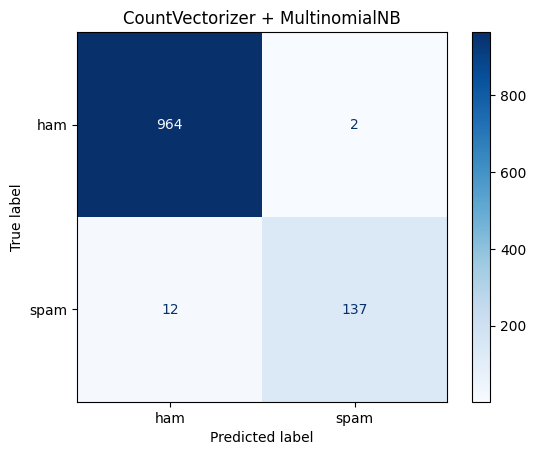

In [27]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    count_pred,
    labels=['ham', 'spam'],
    display_labels=['ham', 'spam'],
    cmap='Blues',
    values_format='d'
)
plt.title('CountVectorizer + MultinomialNB')
plt.show()

## Cell 9 - Repeat the workflow with TF-IDF

Now change **only the text representation**. Use the same training/test split and the same classifier type.

**Complete the TODO lines.**

In [28]:
tfidf_vectorizer = TfidfVectorizer()

# TODO 9: fit/transform training text and transform test text
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

tfidf_model = MultinomialNB()

# TODO 10: fit the model and make predictions
tfidf_model.fit(X_train_tfidf, y_train)
tfidf_pred = tfidf_model.predict(X_test_tfidf)

## Cell 10 - Compare CountVectorizer and TF-IDF

Create the second set of metrics and compare the two representations on the **same test set**.

In [29]:
tfidf_result = evaluate_predictions(y_test, tfidf_pred, 'TF-IDF + MNB')

comparison = pd.DataFrame([count_result, tfidf_result]).set_index('Model')
comparison.round(4)

,Accuracy,Precision,Recall,F1
Model,,,,
CountVectorizer + MNB,0.9874,0.9856,0.9195,0.9514
TF-IDF + MNB,0.9605,1.0000,0.7047,0.8268


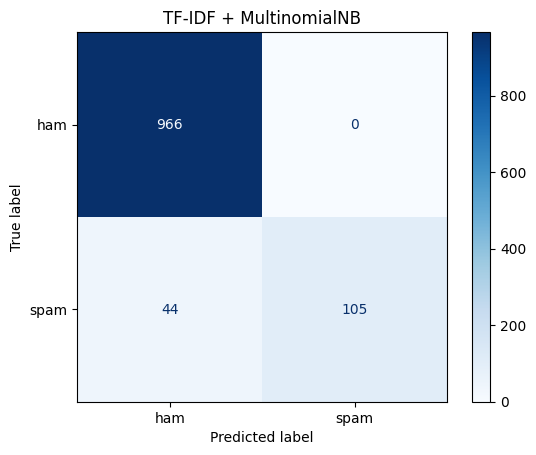

In [30]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    tfidf_pred,
    labels=['ham', 'spam'],
    display_labels=['ham', 'spam'],
    cmap='Blues',
    values_format='d'
)
plt.title('TF-IDF + MultinomialNB')
plt.show()

## Cell 11 - Test your own SMS messages

Create at least **two** messages: one that you expect to be spam and one that you expect to be ham. Compare the predictions from the two models.

**Replace the example messages if you wish.**

In [31]:
my_messages = [
    'Congratulations! Claim your free cash prize now',
    'Can we meet at the library after class today?'
]

count_custom = count_model.predict(count_vectorizer.transform(my_messages))
tfidf_custom = tfidf_model.predict(tfidf_vectorizer.transform(my_messages))

pd.DataFrame({
    'message': my_messages,
    'Count prediction': count_custom,
    'TF-IDF prediction': tfidf_custom
})

,message,Count prediction,TF-IDF prediction
0,Congratulations! Claim your free cash prize now,spam,spam
1,Can we meet at the library after class today?,ham,ham


## Cell 12 - Short questions

Answer briefly in a Markdown cell below.

1. What is the difference between **tokenization** and **vectorization** in this workflow?
2. Compare the CountVectorizer and TF-IDF results. Did one representation perform better on this test set? Support your answer using the generated metrics.
3. From the confusion matrix, which error is more common: a spam message predicted as ham, or a ham message predicted as spam?

### Your answers

1. Answer 01

Tokenization is the process of splitting a raw text string into its individual components or tokens (words). The string is normalized with rules such as lowercasing and removing punctuation.   

Vectorization is the process of mapping those tokenized words into a numerical array or sparse matrix representation (e.g. counts or tf-idf values of terms) that is suitable for model training.

For example, in this workflow, `analyzer()` extracts the individual words from an SMS (tokenization), while `CountVectorizer` or `TfidfVectorizer` converts those words into a matrix of feature counts or weights (vectorization).

<br/>

2. Answer 02

CountVectorizer + MultinomialNB performs better on this dataset.

The TF-IDF + MultinomialNB has a higher Precision (~ 100%) but has a much lower Recall (~ 72%) and a lower F1-Score (~ 84%). Overall, the CountVectorizer performs better in terms of Recall (~93%) and F1-score (~93%), as raw frequency counts retain strong probabilistic signals for shorter SMS text messages.

<br/>

3. Answer 03

The most common error is a spam message predicted as ham (False Negative) which is much more common than a ham message predicted as spam (False Positive).
